# Learner Profiles: a Decision Tree with Guys

Use learner attributes and a combined skill score to predict the dataset’s binary `target` column. This lesson focuses on preparing inputs and interpreting a small tree.

### Topics
- Encode categorical features
- Create a skill score
- Train a tree with limited depth
- Predict example profiles and trace decision rules

**Question for the lesson:** How does the tree use learner features to predict `target`?

> **Estimated time: 60 min**

## 1 · Import the tools and load the table

Keep `barobach.csv` in the same folder as this notebook. Inspect the learner records before choosing the model inputs.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree

In [2]:
df = pd.read_csv('barobach.csv')
df.head()

,name,age,gender,education_level,education_status,major,city,marital_status,numpy,pandas,matplotlib,machine_learning,deep_learning,sql,target
0,آرمین,22,male,bachelor,in_progress,mathematics,Mashhad,NaN,1,1,1,1,1,1,0
1,آریان عمرانی,23,male,bachelor,completed,computer_engineering,Mashhad,NaN,0,0,0,0,0,1,1
2,امیرحسین رضازاده حنایی,26,male,master,in_progress,computer_science,Mashhad,NaN,1,1,1,1,1,1,1
3,امیررضا,22,male,bachelor,in_progress,computer_engineering,Mashhad,NaN,1,1,1,1,1,1,0
4,ساجده,26,female,master,completed,mathematics,Tehran,single,1,1,1,1,1,1,0


## 2 · Encode categories and create a skill score

Fill missing education and marital-status labels with `unknown`, then convert categories into integers. `skill_score` counts how many of the six listed skills are marked as `1`.

The codes for `major` and `city` depend on the categories in this table. Record the mappings when interpreting new samples; a larger category code does not mean a higher level.

In [3]:
# Fill missing text values
df['education_level'] = df['education_level'].fillna('unknown')
df['marital_status'] = df['marital_status'].fillna('unknown').replace(' ', 'unknown')

# Convert simple categories to numbers
df['gender'] = df['gender'].map({'female': 0, 'male': 1})
df['education_level'] = df['education_level'].map({'unknown': 0, 'bachelor': 1, 'master': 2, 'phd': 3})

df['education_status'] = df['education_status'].map({'in_progress': 0, 'completed': 1})
df['marital_status'] = df['marital_status'].map({'unknown': 0, 'single': 1, 'married': 2})

# Convert multi-value categories to integer codes
for column in ['major', 'city']:
    df[column] = df[column].astype('category').cat.codes

skill_columns = [
    'numpy', 'pandas', 'matplotlib',
    'machine_learning', 'deep_learning', 'sql'
]
df[skill_columns + ['target']] = df[skill_columns + ['target']].astype(int)
df['skill_score'] = df[skill_columns].sum(axis=1)

df.head()

,name,age,gender,education_level,education_status,major,city,marital_status,numpy,pandas,matplotlib,machine_learning,deep_learning,sql,target,skill_score
0,آرمین,22,1,1,0,6,0,0,1,1,1,1,1,1,0,6
1,آریان عمرانی,23,1,1,1,1,0,0,0,0,0,0,0,1,1,1
2,امیرحسین رضازاده حنایی,26,1,2,0,2,0,0,1,1,1,1,1,1,1,6
3,امیررضا,22,1,1,0,1,0,0,1,1,1,1,1,1,0,6
4,ساجده,26,0,2,1,6,1,1,1,1,1,1,1,1,0,6


## 3 · Choose features and target

`X` contains eight learner features; `y` is the existing binary `target` column. Exclude `name`, which identifies the learner. The individual skill columns are represented by their combined `skill_score`. The notebook does not define the real-world meaning of classes `0` and `1`.

In [4]:
features = [
    'age', 'gender', 'education_level', 'education_status',
    'major', 'city', 'marital_status', 'skill_score',
]

X = df[features]
y = df['target']

print('Features:')
display(X.head())
print('Target:')
display(y.head())

Features:


,age,gender,education_level,education_status,major,city,marital_status,skill_score
0,22,1,1,0,6,0,0,6
1,23,1,1,1,1,0,0,1
2,26,1,2,0,2,0,0,6
3,22,1,1,0,1,0,0,6
4,26,0,2,1,6,1,1,6


Target:


0    0
1    1
2    1
3    0
4    0
Name: target, dtype: int64

## 4 · Train the Decision Tree

Fit the classifier on all available rows. `max_depth=5` limits how many levels of splits the tree can learn, and `random_state=42` makes training reproducible. The first plot gives a quick view of the rules.

This code does not create a train/test split or calculate accuracy, so it cannot establish performance on unseen learners.

In [5]:
decision_tree = tree.DecisionTreeClassifier(max_depth=5, random_state=42)
decision_tree = decision_tree.fit(X, y)

## 5 · Predict example learner profiles

Each sample must contain the eight features in the same order as `features`. The DataFrame example preserves column names and makes the inputs easier to read. Its profile is the same as the preceding list example.

Use the category mappings from preprocessing to interpret these numbers. The returned `0` or `1` is a model prediction, not an observed result for the sample.

In [6]:
sample = pd.DataFrame([{
	'age': 32,
	'gender': 1,
	'education_level': 1,
	'education_status': 1,
	'major': 1,
	'city': 0,
	'marital_status': 0,
	'skill_score': 6
}])

decision_tree.predict(sample)

array([1])

In [7]:
sample = pd.DataFrame([{
    'age': 40,
    'gender': 1,
    'education_level': 1,
    'education_status': 1,
    'major': 1,
    'city': 0,
    'marital_status': 1,
    'skill_score': 2,
}])

decision_tree.predict(sample)

array([0])

## 6 · Read the tree

The larger, colored plot makes each decision easier to inspect. A split sends values at or below its threshold to the left and larger values to the right. `samples` counts training rows, `value` shows class counts, and `class` is the predicted label at a node.

### Pause & predict

Choose one sample above and trace its path through the tree. Which feature makes the first decision, and which leaf supplies the prediction?

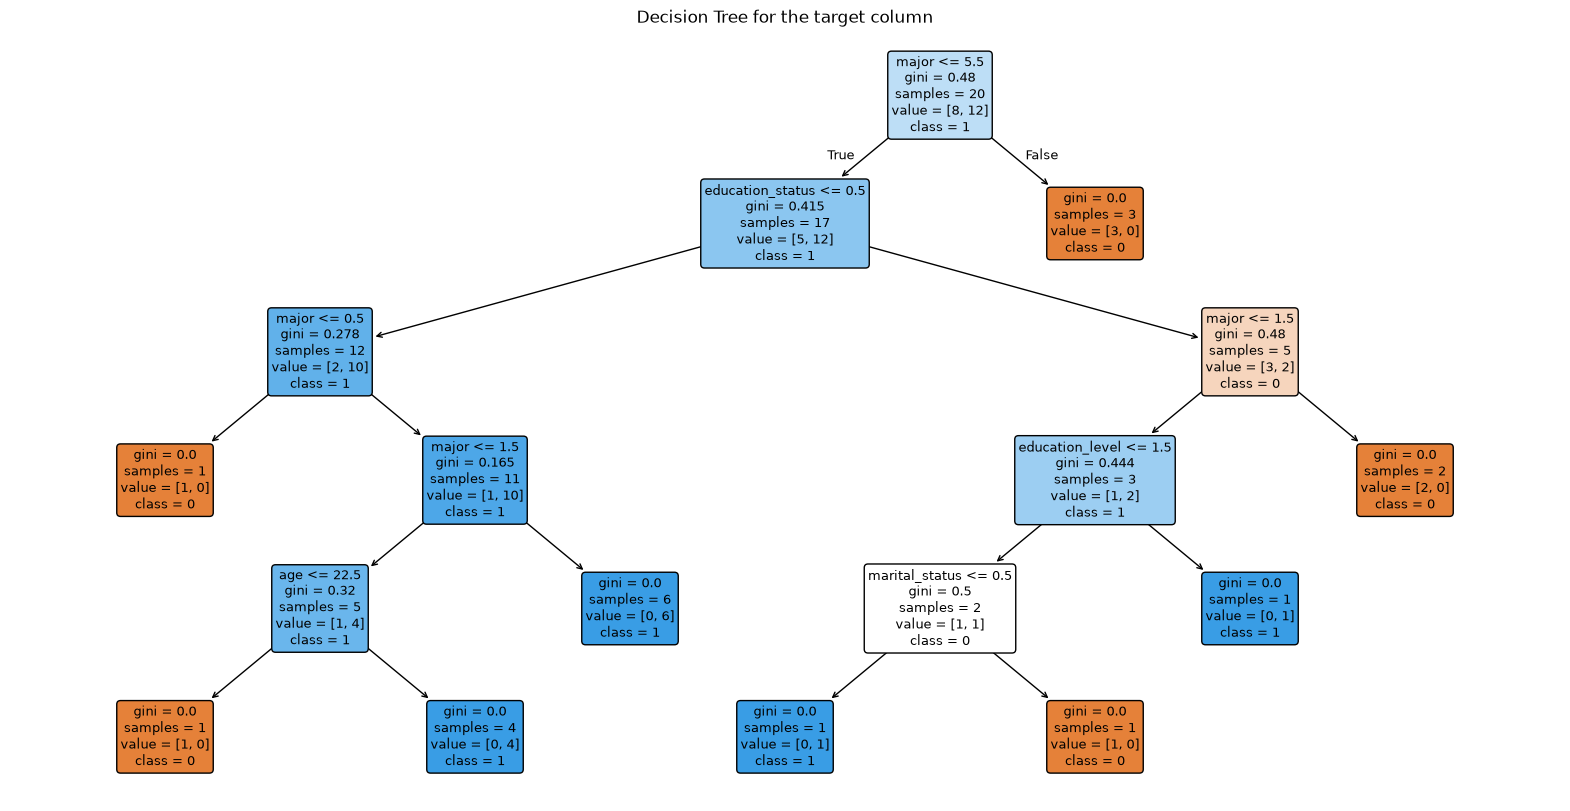

In [8]:
plt.figure(figsize=(20, 10))
tree.plot_tree(
    decision_tree,
    feature_names=features,
    class_names=['0', '1'],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title('Decision Tree for the target column')
plt.show()

## Key takeaways

- A Decision Tree learns if/then rules from labeled examples.
- Category codes must be interpreted using the original mappings.
- Summing binary skill indicators creates a simple engineered feature.
- A small tree is easier to inspect, but a separate test set is still needed to evaluate it.